# Random sampling: searching for low-energy configurations

In `01_disordered_structure_tools.ipynb` we saw that a disordered structure has far too many ordered configurations to check one by one. Usually we care most about the ones with the lowest energy. Those are the orderings most likely to form in the real material, and they make good starting points for more accurate (and more expensive) calculations like DFT.

The simplest way to look for them is *random sampling*:

1. Generate a random ordered configuration.
2. Calculate its energy.
3. Repeat many times, and keep the lowest-energy configurations.

`random_energy_sampling` does this, and also removes symmetric copies (section 3 of the previous notebook), so every configuration it returns is a different structure.

We'll use spinel Li4Ti5O12 (LTO) from the previous notebook. The next notebook, `03_simple_MC_example.ipynb`, searches the same structure with Monte Carlo.

In [1]:
# Imports
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from pymatgen.core import Structure

from disorderly import (
    PrecomputedEwald,
    describe_wyckoff_sites,
    disordered_ewald_energy,
    disordered_site_groups,
    load_configurations,
    random_energy_sampling,
    random_ordered_configuration,
    save_configurations,
    save_structures,
    structure_from_ordering_key,
    supercell_multiplier,
    symmetrically_equivalent,
)
from disorderly.cli.run_random_sampling import run_random_sampling

structures_dir = Path("../tests/test_structures")
output_dir = Path("random_sampling_out") # Files written by this notebook go here

## 1. Set up the structure

In the previous notebook we made LTO's occupancies fit by stacking three copies of its unit cell in a row (3×1×1). That supercell is long and thin. Here we use a supercell with the same number of sites but a more even shape: 2×2×3 copies of LTO's *primitive cell*, the smallest cell that repeats to build the crystal.

We call this the *parent* structure: the disordered structure that every ordered configuration is built from.

In [2]:
lto = Structure.from_file(structures_dir / "LTO_COD_1001098.cif")
print(f"initial LTO structure: {len(lto)} sites, side lengths {', '.join(f'{x:.1f}' for x in lto.lattice.abc)} Å")
print(describe_wyckoff_sites(lto), '\n')

parent = lto.get_primitive_structure() # The smallest cell that repeats to build the crystal: 14 sites
parent.make_supercell([2, 2, 3]) # 2 x 2 x 3 copies of it: 168 sites

print(f"parent: {len(parent)} sites, side lengths {', '.join(f'{x:.1f}' for x in parent.lattice.abc)} Å")
print(f"supercell multiplier: {supercell_multiplier(parent)}") # 1 means the occupancies fit this cell
for group in disordered_site_groups(parent):
    counts = ", ".join(f"{n} {species}" for species, n in group.counts.items())
    print(f"{group.n_sites} mixed sites, holding {counts} in every ordered configuration")

initial LTO structure: 56 sites, side lengths 8.4, 8.4, 8.4 Å
Wyckoff sites for Li10.6672 Ti13.3328 O32
label          species                        sites in cell   disordered?  ordered configuration
Li_8a          Li+                                        8   no           -
Li-Ti_16d      Li+:0.167, Ti4+:0.833                     16   yes          3 Li+, 13 Ti4+
O_32e          O2-                                       32   no           - 

parent: 168 sites, side lengths 11.8, 11.8, 17.7 Å
supercell multiplier: 1
48 mixed sites, holding 8 Li+, 40 Ti4+ in every ordered configuration


For the unit cell, the last column of the table rounds the 2.67 Li on the 16d sites up to 3. That is the problem from the previous notebook, and the reason we need a supercell. The 3×1×1 supercell's sides are 25.1, 8.4, and 8.4 Å, so this one is much closer to equal in every direction. In the parent, every ordered configuration puts exactly 8 Li and 40 Ti on the 48 mixed sites. The other Li and all the O never change.

## 2. An energy model

To rank configurations we need their energies. DFT is the most accurate option, but it takes minutes to hours per structure, which is far too slow for thousands of configurations. Here we use the *Ewald energy*: the electrostatic energy of the crystal, treating every ion as a point charge equal to its oxidation state (Li+ = +1, Ti4+ = +4, O2- = −2). The structure must already carry oxidation states, as the LTO file does. If it doesn't, the package raises an error rather than guessing them.

The Ewald energy ignores everything except electrostatics, so it's a rough model. But it captures the main reason Li and Ti order on the mixed sites: Ti4+ carries much more charge than Li+, so arrangements that spread the charge evenly have lower energy. It is also fast.

<details>
<summary>How the Ewald energy is calculated</summary>

The electrostatic energy of a crystal is a sum of Coulomb interactions $q_i q_j / r_{ij}$ over every pair of ions, including all their periodic copies. Because $1/r$ decays slowly, this sum over an infinite crystal converges very poorly. The Ewald method splits it into a short-range part, summed in real space, and a long-range part, summed in reciprocal space. Both parts converge quickly.

`disordered_ewald_energy` uses pymatgen's `EwaldSummation`. For a partially occupied site, it uses the occupancy-weighted average charge, so it works on disordered structures too. Energies are in eV per cell.

The energy is a quadratic function of the charges, $E = \mathbf{q}^\mathsf{T} M \mathbf{q}$ (plus a correction for charged cells), and the matrix $M$ depends only on the site positions. `PrecomputedEwald` calculates $M$ once, so each new configuration only needs a matrix multiplication.

</details>

In [3]:
example = random_ordered_configuration(parent, np.random.default_rng(0))

start = time.perf_counter()
energy = disordered_ewald_energy(example)
print(f"disordered_ewald_energy: {energy:.2f} eV  ({1000 * (time.perf_counter() - start):.1f} ms)")

disordered_ewald_energy: -5993.81 eV  (24.7 ms)


For thousands of configurations, `PrecomputedEwald` is faster. In all of our configurations the atoms sit on the same positions; only which species is on which site changes. So the part of the calculation that depends only on the positions can be done once, up front:

In [4]:
ewald = PrecomputedEwald(parent) # Does the position-only part of the calculation once

start = time.perf_counter()
energy = ewald(example)
print(f"PrecomputedEwald:        {energy:.2f} eV  ({1000 * (time.perf_counter() - start):.1f} ms)")

PrecomputedEwald:        -5993.81 eV  (0.6 ms)


Same energy, many times faster. `ewald` is now an *energy evaluator*: a function that takes a structure and returns its energy. `random_energy_sampling` accepts any energy evaluator, so you can switch to a more accurate model (section 6) without changing anything else.

## 3. What do random configurations look like?

Before searching, let's look at the energies of 2,000 random configurations:

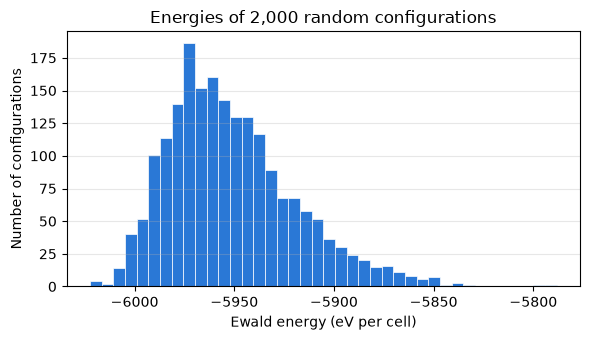

average -5951.3 eV, standard deviation 32.0 eV, lowest -6022.4 eV


In [5]:
rng = np.random.default_rng(1)
random_energies = np.array([ewald(random_ordered_configuration(parent, rng)) for _ in range(2000)])

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(random_energies, bins=40, color="#2a78d6", edgecolor="white", linewidth=0.5)
ax.set_xlabel("Ewald energy (eV per cell)")
ax.set_ylabel("Number of configurations")
ax.set_title("Energies of 2,000 random configurations")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

print(f"average {random_energies.mean():.1f} eV, standard deviation {random_energies.std():.1f} eV, lowest {random_energies.min():.1f} eV")

Most random configurations land near the middle of this distribution. The low-energy configurations we want are out in the left tail, so random sampling only finds them rarely. Keep this in mind for the Monte Carlo notebook.

## 4. Run random sampling

`random_energy_sampling` generates `n_attempts` random configurations, calculates each one's energy with the evaluator, removes symmetric copies, and returns the `n_return` lowest-energy distinct configurations:

In [6]:
results = random_energy_sampling(
    parent,
    ewald, # The energy evaluator
    n_attempts=2000, # Number of random configurations to try
    n_return=5, # Number of lowest-energy distinct configurations to return
    seed=0, # Fixes the random numbers, so rerunning gives the same result
    verbose=False,
)

for config in results:
    print(f"attempt {config.step:>4d} | energy {config.energy:.2f} eV")

attempt  690 | energy -6019.48 eV
attempt 1649 | energy -6018.30 eV
attempt  669 | energy -6017.69 eV
attempt  472 | energy -6017.35 eV
attempt 1215 | energy -6016.97 eV


`step` is the attempt at which each configuration was found. Results are sorted from lowest to highest energy. When the Ewald energy is all you need, `random_ewald_sampling(parent, n_attempts=..., ...)` is a shortcut that does the same thing without passing an evaluator.

To save memory on long runs, the sampler doesn't keep every configuration it tries. It keeps a pool of the lowest-energy candidates (`candidate_pool_size`, by default 5 × `n_return` or 50, whichever is larger) and removes symmetric copies from that pool at the end. If many of the low-energy candidates turn out to be copies of each other, you can get fewer than `n_return` results; increasing `candidate_pool_size` fixes that.

## 5. Check and save the results

No two returned configurations should be the same structure. `symmetrically_equivalent` checks whether two ordered structures are related by symmetry:

In [7]:
duplicates = [
    (i, j)
    for i in range(len(results))
    for j in range(i + 1, len(results))
    if symmetrically_equivalent(results[i].structure, results[j].structure)
]
print(f"pairs of returned configurations that are the same structure: {duplicates}")

pairs of returned configurations that are the same structure: []


Each result also has an *ordering key*: a short code recording which species sits on each mixed site. Together with the parent structure, the key is enough to rebuild the configuration, which makes it a compact way to store or share many configurations.

In [8]:
best = results[0]
print(f"ordering key: {best.ordering_key}")

rebuilt = structure_from_ordering_key(parent, best.ordering_key) # Rebuild the configuration from the parent and key
print(f"rebuilt structure matches: {symmetrically_equivalent(rebuilt, best.structure)}")

ordering key: ok1___ez3f_t
rebuilt structure matches: True


`save_configurations` writes the results to a JSON file: each configuration's energy, properties, and ordering key. To keep the file small it doesn't store the full structures (pass `include_structures=True` if you want them), so `load_configurations` needs the parent to rebuild them from their keys. `save_structures` writes each structure as a CIF file that other programs can open.

In [9]:
output_dir.mkdir(exist_ok=True)
json_path = save_configurations(results, output_dir / "sampled_configurations.json")
cif_paths = save_structures([config.structure for config in results], output_dir / "structures", prefix="ordered")
print(f"saved {json_path} and {len(cif_paths)} CIF files in {cif_paths[0].parent}")

reloaded = load_configurations(json_path, parent=parent) # The parent is needed to rebuild structures from their keys
print(f"reloaded {len(reloaded)} configurations, lowest energy {reloaded[0].energy:.2f} eV")

saved random_sampling_out/sampled_configurations.json and 5 CIF files in random_sampling_out/structures
reloaded 5 configurations, lowest energy -6019.48 eV


## 6. Using a different energy model

An energy evaluator can also return a dictionary with an `"energy"` key plus any other properties you want saved with each configuration. As an example, we'll also record how many pairs of Li sit on neighboring mixed sites. Neighboring mixed sites are 2.95 Å apart, and no other pair of Li sites is closer than 3.4 Å, so counting Li–Li pairs closer than 3 Å picks out exactly these neighbors.

In [10]:
def count_li_li_neighbors(structure):
    """Number of Li-Li pairs closer than 3 A, i.e. Li on neighboring mixed (16d) sites."""
    li = [i for i, site in enumerate(structure) if site.specie.symbol == "Li"]
    distances = structure.distance_matrix[np.ix_(li, li)]
    return int(((distances > 0.1) & (distances < 3.0)).sum() // 2) # Each pair appears twice in the matrix


def ewald_and_li_pairs(structure):
    return {"energy": ewald(structure), "li_li_neighbors": count_li_li_neighbors(structure)}


results_with_pairs = random_energy_sampling(parent, ewald_and_li_pairs, n_attempts=2000, n_return=5, seed=0, verbose=False)
for config in results_with_pairs:
    print(f"energy {config.energy:.2f} eV | Li-Li neighbor pairs {config.properties['li_li_neighbors']}")

print(f"\nLi-Li neighbor pairs in the random configuration from section 2: {count_li_li_neighbors(example)}")

energy -6019.48 eV | Li-Li neighbor pairs 0
energy -6018.30 eV | Li-Li neighbor pairs 0
energy -6017.69 eV | Li-Li neighbor pairs 0
energy -6017.35 eV | Li-Li neighbor pairs 0
energy -6016.97 eV | Li-Li neighbor pairs 0

Li-Li neighbor pairs in the random configuration from section 2: 1


With the same seed, the sampler tries the same configurations, so the energies match section 4. None of the lowest-energy configurations has Li on neighboring mixed sites. This is the electrostatic picture from section 2: Li+ carries less positive charge than the Ti4+ around it, so two Li side by side leave a patch of the crystal short of positive charge.

For more realistic energies, the package includes evaluators built on machine-learned interatomic potentials (MLIPs), which approach DFT accuracy at a small fraction of the cost. They are optional extras (`pip install "disorderly[mace]"` or `"disorderly[chgnet]"`) and plug in exactly like `ewald`:

```python
from disorderly import MACEEnergyEvaluator

mace = MACEEnergyEvaluator(model_path="/path/to/mace.model", device="cpu", relax=True)
results = random_energy_sampling(parent, mace, n_attempts=1000, n_return=10, seed=0)
```

With `relax=True` each configuration's atomic positions are relaxed before its energy is calculated. That is more realistic, since real atoms shift slightly to accommodate their neighbors, but much slower.

## 7. Running from the command line

For long runs, for example on a computing cluster, the `run-random-sampling` command does the same thing as `random_energy_sampling` without a notebook. It takes two arguments: the parent structure file, and a Python *settings file* that defines the energy evaluator and the sampling options.

Below we write the parent and a small settings file, then call `run_random_sampling`, the function behind the command. From a terminal, the equivalent command would be:

```bash
run-random-sampling random_sampling_out/LTO_supercell.cif random_sampling_out/settings.py
```

The settings file uses `disordered_ewald_energy` rather than `PrecomputedEwald`, because a settings file doesn't receive the parent structure. `src/disorderly/cli/random_sampling_settings_reference.py` is a fuller reference file, listing every option, set up for MACE.

In [11]:
parent_path = output_dir / "LTO_supercell.cif"

settings_path = output_dir / "settings.py"
settings_path.write_text('''
from disorderly import disordered_ewald_energy

energy_evaluator = disordered_ewald_energy # Any function that takes a structure and returns an energy
n_attempts = 100
n_return = 3
seed = 0
output_dir = "cli_results" # Relative to this settings file
verbose = False
''')

with warnings.catch_warnings():
    # Writing and reading the CIF gives two harmless pymatgen warnings: mixed sites list each species with
    # the same label, and coordinates are rounded slightly. The structure reads back correctly.
    warnings.filterwarnings("ignore", message="Site labels are not unique")
    warnings.filterwarnings("ignore", message="Issues encountered while parsing CIF")
    parent.to(filename=str(parent_path))
    cli_results = run_random_sampling(parent_path, settings_path)

Found 3 symmetrically distinct configurations; saved to random_sampling_out/cli_results
  step      33  energy -6006.952681 eV  key ok1__ub3-P__
  step      55  energy -6001.458315 eV  key ok1_Pt27___3
  step      20  energy -5997.379721 eV  key ok1_79_4f_v-


## Summary

- Random sampling generates random ordered configurations, calculates their energies, and keeps the lowest-energy distinct ones (`random_energy_sampling`).
- The Ewald energy is a fast, rough energy model based on electrostatics. `PrecomputedEwald` speeds it up for configurations on fixed positions.
- Any function that takes a structure and returns an energy can be used as the energy evaluator, including MLIPs like MACE and CHGNet.
- Results can be checked for symmetric copies, saved, reloaded, and rebuilt from their ordering keys.

Random sampling's weakness is that every attempt starts from scratch, so it rarely reaches the low-energy tail of the distribution. Next, `03_simple_MC_example.ipynb` uses Monte Carlo to search the same structure, building on each step instead of starting over.